# 04 · Preparación y modelado — Adopción de IA en empresas

Este cuaderno continúa la descriptiva del dataset Global AI Adoption & Workforce Impact. Construye una regresión para estimar la tasa de adopción de IA (`ai_adoption_rate`) a partir de atributos generales de la empresa y del período. Sigue un flujo de preparación ajustado solo con entrenamiento y evalúa sobre empresas que el modelo no vio.

## Pregunta, unidad y alcance

**Pregunta:** ¿cuánto ayudan el país, la industria, la cantidad de empleados, los ingresos, la antigüedad y el período a estimar la tasa de adopción de IA de una empresa?

**Unidad de análisis:** una fila por empresa y trimestre. El archivo contiene un panel no balanceado: hay empresas con 10 a 16 períodos.

**Objetivo:** regresión de `ai_adoption_rate` (0–100). El ejercicio estima asociación predictiva dentro de los años observados; no afirma causalidad ni pronostica años futuros.

**Exclusiones para evitar fuga por el objetivo:** `ai_adoption_stage` es la tasa de adopción discretizada en tramos; `company_id` identifica empresas y se reserva para separar grupos. También se excluyen otras medidas de actividad e impacto de IA, porque el dataset no documenta cuándo se observan respecto del resultado. No se incluyen `region` junto con `country` ni `company_size` junto con `num_employees`: se verificó que cada par contiene información redundante en esta base.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)
SEMILLA = 2026
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

# Busca la raíz que contiene proyecto_equipo/datos aunque Jupyter se abra desde la raíz del repo.
RAIZ = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'proyecto_equipo' / 'datos').is_dir())
PROYECTO = RAIZ / 'proyecto_equipo'
RUTA = PROYECTO / 'datos' / 'derivados' / 'ai_company_adoption_limpio.parquet'
assert RUTA.exists(), f'No se encuentra {RUTA}: ejecutar primero 02_limpieza_ai.ipynb'
print('Raíz del repositorio:', RAIZ)
print('Parquet:', RUTA.relative_to(RAIZ))

Raíz del repositorio: /Users/agus/Desktop/Facultad/CUARTO/Aprendizaje automatico/aa-2026-entorno
Parquet: proyecto_equipo/datos/derivados/ai_company_adoption_limpio.parquet


## 1. Carga y auditoría del panel

Antes de modelar se comprueba el tamaño, la cantidad de empresas, la repetición de entidades y los duplicados exactos. Las filas repetidas por empresa hacen inadecuada una partición aleatoria por fila para medir el desempeño en empresas nuevas.

In [2]:
df = pd.read_parquet(RUTA)
assert df.shape == (150_000, 43)
assert not df.duplicated().any()
frecuencia = df.groupby('company_id').size()
print(f'{len(df):,} filas · {df.company_id.nunique():,} empresas · {df.survey_year.min()}–{df.survey_year.max()}')
print(f'Filas por empresa: mínimo {frecuencia.min()}, mediana {frecuencia.median():.0f}, máximo {frecuencia.max()}')
print('Faltantes en columnas candidatas:', int(df[['ai_adoption_rate', 'survey_year', 'company_age', 'num_employees', 'annual_revenue_usd_millions', 'country', 'region', 'industry', 'company_size']].isna().sum().sum()))
assert df.groupby('country')['region'].nunique().max() == 1
assert df.groupby('num_employees')['company_size'].nunique().max() == 1
print('Redundancias verificadas: region↔country y company_size↔num_employees')

150,000 filas · 10,000 empresas · 2023–2026
Filas por empresa: mínimo 10, mediana 15, máximo 16
Faltantes en columnas candidatas: 0
Redundancias verificadas: region↔country y company_size↔num_employees


## 2. Definir el objetivo y revisar la fuga

La predicción se limita a variables de contexto general. No se usa la etapa de adopción porque se construye cortando la propia tasa objetivo. Tampoco se usa el identificador como predictor: serviría para reconocer registros, no para describir una empresa nueva.

Se separarán empresas completas. Dentro del conjunto de entrenamiento, `GroupKFold` mantendrá juntas las filas de cada empresa al elegir hiperparámetros. El conjunto final queda apartado hasta la evaluación.

In [3]:
objetivo = 'ai_adoption_rate'
columnas_categoricas = ['country', 'industry']
columnas_log = ['num_employees', 'annual_revenue_usd_millions']
columnas_escaladas = ['company_age', 'survey_year']
columnas = columnas_log + columnas_escaladas + columnas_categoricas

X = df[columnas].copy()
y = pd.to_numeric(df[objetivo], errors='raise').astype(float)
grupos = df['company_id'].astype('string')
assert X.notna().all().all() and y.notna().all()
assert (X[columnas_log] >= 0).all().all(), 'log1p requiere valores no negativos'
print('Predictores:', columnas)
print('Se excluyen del modelo:', ['company_id', 'ai_adoption_stage', 'region (redundante con country)', 'company_size (derivada de num_employees)', 'variables de resultado/actividad de IA'])

# Evidencia para comprimir la cola: comparar percentiles con el máximo.
display(X[columnas_log].describe(percentiles=[0.50, 0.90, 0.99]).T.round(2))

Predictores: ['num_employees', 'annual_revenue_usd_millions', 'company_age', 'survey_year', 'country', 'industry']
Se excluyen del modelo: ['company_id', 'ai_adoption_stage', 'region (redundante con country)', 'company_size (derivada de num_employees)', 'variables de resultado/actividad de IA']


,count,mean,std,min,50%,90%,99%,max
num_employees,150000.0,2342.38,4754.42,10.00,349.00,10602.00,18837.00,19970.00
annual_revenue_usd_millions,150000.0,1180.35,2391.47,1.01,184.16,5316.19,9505.21,9996.73


## 3. Partición por empresa

Una partición aleatoria por fila deja casi todas las empresas tanto en entrenamiento como en prueba. Esa evaluación responde a una pregunta más fácil: predecir nuevos trimestres de empresas conocidas. Como aquí interesa generalizar a empresas no vistas, la evaluación principal separa grupos completos.

In [4]:
idx_ent_azar, idx_pru_azar = train_test_split(np.arange(len(df)), test_size=0.20, random_state=SEMILLA)
empresas_ent_azar = set(grupos.iloc[idx_ent_azar])
empresas_pru_azar = set(grupos.iloc[idx_pru_azar])
solapadas_azar = empresas_ent_azar & empresas_pru_azar
print(f'Partición aleatoria por fila: {len(solapadas_azar):,} empresas aparecen a ambos lados')

partidor = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
idx_ent, idx_pru = next(partidor.split(X, y, groups=grupos))
X_ent, X_pru = X.iloc[idx_ent], X.iloc[idx_pru]
y_ent, y_pru = y.iloc[idx_ent], y.iloc[idx_pru]
grupos_ent, grupos_pru = grupos.iloc[idx_ent], grupos.iloc[idx_pru]
solapadas = set(grupos_ent) & set(grupos_pru)
assert not solapadas
print(f'Partición por empresa: entrenamiento {len(X_ent):,} filas / {grupos_ent.nunique():,} empresas; prueba {len(X_pru):,} filas / {grupos_pru.nunique():,} empresas; solapadas: {len(solapadas)}')

Partición aleatoria por fila: 9,650 empresas aparecen a ambos lados


Partición por empresa: entrenamiento 119,969 filas / 8,000 empresas; prueba 30,031 filas / 2,000 empresas; solapadas: 0


## 4. Preparación dentro del flujo

- `num_employees` e ingresos son no negativos y tienen escalas amplias; `log1p` comprime la cola sin borrar observaciones extremas. Los atípicos plausibles se conservan.
- Edad de la empresa y año se estandarizan. Los centros y amplitudes los aprende `StandardScaler` durante `fit`.
- Las categóricas nominales se codifican con indicadores. `handle_unknown='ignore'` permite recibir una categoría no vista al ajustar.
- Los imputadores se incluyen para que el flujo pueda manejar faltantes futuros; en la base actual las columnas seleccionadas están completas.
- `SelectKBest` y `Ridge` también viven dentro del pipeline: la selección y el ajuste se repiten solo con la parte de entrenamiento de cada fold.

In [5]:
numericas_log = Pipeline([
    ('imputar', SimpleImputer(strategy='median')),
    ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('escalar', StandardScaler()),
])
numericas_continuas = Pipeline([
    ('imputar', SimpleImputer(strategy='median')),
    ('escalar', StandardScaler()),
])
categoricas = Pipeline([
    ('imputar', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preparacion = ColumnTransformer([
    ('conteos_ingresos', numericas_log, columnas_log),
    ('edad_periodo', numericas_continuas, columnas_escaladas),
    ('nominales', categoricas, columnas_categoricas),
], remainder='drop')

flujo = Pipeline([
    ('preparar', preparacion),
    ('seleccionar', SelectKBest(score_func=f_regression)),
    ('regresion', Ridge()),
])
print('Pipeline:', [nombre for nombre, _ in flujo.steps])

Pipeline: ['preparar', 'seleccionar', 'regresion']


## 5. Selección de hiperparámetros con validación por grupos

La validación cruzada usa cinco particiones agrupadas por `company_id`. Los valores de imputación, escalado, categorías y selección de variables se vuelven a aprender dentro de cada fold. La búsqueda optimiza RMSE; el test final no participa en esa decisión.

In [6]:
cv_grupos = GroupKFold(n_splits=5)
busqueda = GridSearchCV(
    estimator=flujo,
    param_grid={
        'seleccionar__k': [20, 'all'],
        'regresion__alpha': [0.1, 1.0, 10.0, 100.0],
    },
    scoring='neg_root_mean_squared_error',
    cv=cv_grupos,
    n_jobs=1,
    refit=True,
    return_train_score=True,
)
busqueda.fit(X_ent, y_ent, groups=grupos_ent)
print('Mejores parámetros:', busqueda.best_params_)
print(f'RMSE medio en CV agrupada: {-busqueda.best_score_:.2f} puntos porcentuales')

Mejores parámetros: {'regresion__alpha': 100.0, 'seleccionar__k': 'all'}
RMSE medio en CV agrupada: 13.79 puntos porcentuales


## 6. Evaluación final y comparación con el protocolo por fila

Se compara con una línea base que predice la media del entrenamiento. Como demostración, también se mide el mismo modelo con una partición aleatoria por fila: esa segunda cifra no se considera una estimación válida para empresas nuevas porque las entidades se repiten entre ambos lados.

In [7]:
def calcular_metricas(real, estimado):
    return {
        'R²': r2_score(real, estimado),
        'RMSE (pp)': np.sqrt(mean_squared_error(real, estimado)),
        'MAE (pp)': mean_absolute_error(real, estimado),
    }

pred_grupo = busqueda.best_estimator_.predict(X_pru)
base = DummyRegressor(strategy='mean').fit(X_ent, y_ent)
pred_base = base.predict(X_pru)

modelo_fila = clone(busqueda.best_estimator_)
X_ent_f, X_pru_f = X.iloc[idx_ent_azar], X.iloc[idx_pru_azar]
y_ent_f, y_pru_f = y.iloc[idx_ent_azar], y.iloc[idx_pru_azar]
modelo_fila.fit(X_ent_f, y_ent_f)
pred_fila = modelo_fila.predict(X_pru_f)

tabla_metricas = pd.DataFrame({
    'Media del entrenamiento (holdout por empresa)': calcular_metricas(y_pru, pred_base),
    'Ridge (holdout por empresa)': calcular_metricas(y_pru, pred_grupo),
    'Ridge (partición aleatoria por fila, solo demostración)': calcular_metricas(y_pru_f, pred_fila),
}).T.round(3)
display(tabla_metricas)

,R²,RMSE (pp),MAE (pp)
Media del entrenamiento (holdout por empresa),-0.000,14.624,11.716
Ridge (holdout por empresa),0.098,13.889,11.134
"Ridge (partición aleatoria por fila, solo demostración)",0.102,13.702,10.949


**Resultado de esta ejecución:** la regresión con holdout por empresa obtuvo R² = 0,098, RMSE = 13,889 y MAE = 11,134 puntos porcentuales; la línea base tuvo RMSE = 14,624 y MAE = 11,716. La validación cruzada agrupada estimó un RMSE medio de 13,79. La búsqueda eligió `alpha=100` y conservó todas las variables; reducir a 20 no mejoró el criterio de selección.

La partición aleatoria por fila dio R² = 0,102 y RMSE = 13,702, con 9.650 empresas presentes a ambos lados. La diferencia de métricas en esta ejecución fue pequeña; esa partición sigue sin responder a la pregunta de generalizar a empresas nuevas, por lo que el resultado que se reporta es el holdout por empresa. La prueba final no se utilizó para elegir hiperparámetros.

## 7. Variables seleccionadas y diagnóstico

Los coeficientes describen asociaciones lineales del modelo después de la codificación y el escalado. No son efectos causales. El gráfico de observado contra predicho y el histograma de residuos se generan en esta celda y quedan visibles en el propio cuaderno.

,variable,coeficiente
42,nominales__industry_Technology,6.180
5,nominales__country_Australia,3.510
32,nominales__country_USA,3.157
25,nominales__country_Singapore,3.127
26,nominales__country_South Africa,-3.078
7,nominales__country_Canada,2.973
22,nominales__country_Nigeria,-2.922
11,nominales__country_Egypt,-2.774
9,nominales__country_China,-2.730
37,nominales__industry_Finance,2.422


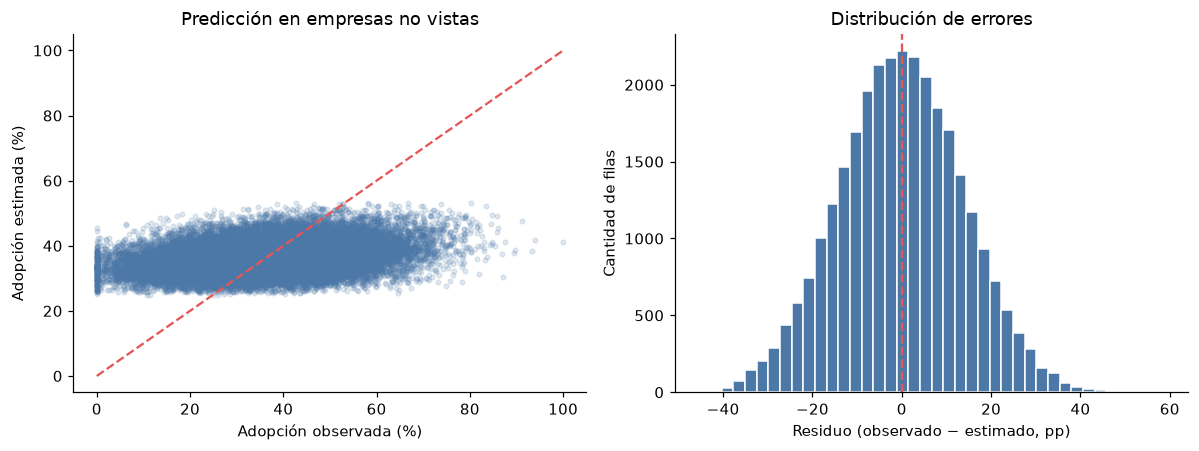

In [8]:
preparador_ajustado = busqueda.best_estimator_.named_steps['preparar']
selector_ajustado = busqueda.best_estimator_.named_steps['seleccionar']
regresion_ajustada = busqueda.best_estimator_.named_steps['regresion']
nombres = preparador_ajustado.get_feature_names_out()
nombres_seleccionados = nombres[selector_ajustado.get_support()]
coeficientes = pd.DataFrame({'variable': nombres_seleccionados, 'coeficiente': regresion_ajustada.coef_})
coeficientes['magnitud'] = coeficientes['coeficiente'].abs()
display(coeficientes.sort_values('magnitud', ascending=False).head(12).drop(columns='magnitud').round(3))

residuos = y_pru.to_numpy() - pred_grupo
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
ejes[0].scatter(y_pru, pred_grupo, alpha=0.16, s=9, color='#4C78A8')
limite = [min(float(y_pru.min()), float(pred_grupo.min())), max(float(y_pru.max()), float(pred_grupo.max()))]
ejes[0].plot(limite, limite, '--', color='#E45756', linewidth=1.5)
ejes[0].set(xlabel='Adopción observada (%)', ylabel='Adopción estimada (%)', title='Predicción en empresas no vistas')
ejes[1].hist(residuos, bins=40, color='#4C78A8', edgecolor='white')
ejes[1].axvline(0, color='#E45756', linestyle='--', linewidth=1.5)
ejes[1].set(xlabel='Residuo (observado − estimado, pp)', ylabel='Cantidad de filas', title='Distribución de errores')
plt.tight_layout()
plt.show()

## Resultado y límites

El resultado que se reporta es el del holdout por empresa, acompañado por la línea base. La partición por fila se conserva solo como demostración de la fuga por entidad.

- La evaluación mezcla los años 2023–2026 en ambos lados; estima desempeño para empresas no vistas dentro de los períodos observados, no para años futuros. Para pronosticar 2027 u otro período futuro hay que separar cronológicamente y entrenar solo con períodos anteriores.
- El dataset es un panel no balanceado y la fuente no documenta cómo fue generado. No se extrapolan estas métricas a toda la población de empresas.
- `ai_adoption_stage` se excluyó por ser una discretización de la respuesta. `company_id` solo se usó para particionar y validar.
- Se conservaron valores extremos plausibles; las transformaciones y selecciones que aprenden parámetros se ajustaron dentro del flujo y de los folds.
- Fuente: Global AI Adoption & Workforce Impact Dataset, Kaggle. El análisis es predictivo/descriptivo y no permite concluir causalidad.